In [2]:
import os
import time
import copy
import numpy as np
import matplotlib.pyplot as plt
from scipy import linalg

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torchvision.utils import make_grid
from torch.ao.quantization import QuantStub, DeQuantStub, fuse_modules

# Ensure deterministic execution for fair cross-precision comparisons
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

# Training uses GPU if available; quantization benchmarks run on CPU (x86 fbgemm / ARM qnnpack)
#device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
quant_backend = "fbgemm" if "fbgemm" in torch.backends.quantized.supported_engines else "qnnpack"
torch.backends.quantized.engine = quant_backend

print(f"Training Device: {device}")
print(f"Quantization Engine: {torch.backends.quantized.engine}")

Training Device: mps
Quantization Engine: qnnpack


In [3]:
LATENT_DIM = 64
BATCH_SIZE = 128

class QuantizableGenerator(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM):
        super().__init__()
        self.quant = QuantStub()
        
        # Project and reshape latent vector: [B, latent_dim, 1, 1] -> [B, 128, 7, 7]
        self.init_fc = nn.Linear(latent_dim, 128 * 7 * 7)
        self.init_bn = nn.BatchNorm1d(128 * 7 * 7)
        self.init_relu = nn.ReLU(inplace=True)
        
        # Upsample Block 1: 7x7 -> 14x14
        self.up1 = nn.Upsample(scale_factor=2, mode='nearest')
        self.block1 = nn.Sequential(
            nn.Conv2d(128, 64, kernel_size=3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True)
        )
        
        # Upsample Block 2: 14x14 -> 28x28
        self.up2 = nn.Upsample(scale_factor=2, mode='nearest')
        self.block2 = nn.Sequential(
            nn.Conv2d(64, 32, kernel_size=3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True)
        )
        
        # Output Conv: 28x28x1
        self.out_conv = nn.Conv2d(32, 1, kernel_size=3, stride=1, padding=1)
        self.out_tanh = nn.Tanh()
        self.dequant = DeQuantStub()

    def forward(self, z):
        x = self.quant(z)
        x = self.init_fc(x)
        x = self.init_bn(x)
        x = self.init_relu(x)
        x = x.reshape(-1, 128, 7, 7)
        
        x = self.up1(x)
        x = self.block1(x)
        
        x = self.up2(x)
        x = self.block2(x)
        
        x = self.out_conv(x)
        x = self.out_tanh(x)
        x = self.dequant(x)
        return x

    def fuse_model(self):
        """Fuses Conv+BN+ReLU blocks in-place for Static INT8 inference."""
        fuse_modules(self.block1, ['0', '1', '2'], inplace=True)
        fuse_modules(self.block2, ['0', '1', '2'], inplace=True)


class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=4, stride=2, padding=1), # 14x14
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(32, 64, kernel_size=4, stride=2, padding=1), # 7x7
            nn.BatchNorm2d(64),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 1),
            nn.Sigmoid()
        )

    def forward(self, img):
        return self.net(img)

In [4]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize([0.5], [0.5]) # Map [0, 1] -> [-1, 1] for Tanh
])

dataset = torchvision.datasets.FashionMNIST(
    root="./data", train=True, download=True, transform=transform
)
dataloader = torch.utils.data.DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=True)

G_fp32 = QuantizableGenerator(LATENT_DIM).to(device)
D = Discriminator().to(device)

criterion = nn.BCELoss()
opt_G = optim.Adam(G_fp32.parameters(), lr=2e-4, betas=(0.5, 0.999))
opt_D = optim.Adam(D.parameters(), lr=2e-4, betas=(0.5, 0.999))

EPOCHS = 5
print("Training FP32 Baseline GAN...")
for epoch in range(EPOCHS):
    for i, (real_imgs, _) in enumerate(dataloader):
        real_imgs = real_imgs.to(device)
        valid = torch.ones(BATCH_SIZE, 1, device=device)
        fake = torch.zeros(BATCH_SIZE, 1, device=device)

        # --- Train Discriminator ---
        opt_D.zero_grad()
        z = torch.randn(BATCH_SIZE, LATENT_DIM, device=device)
        fake_imgs = G_fp32(z).detach()
        loss_D = 0.5 * (criterion(D(real_imgs), valid) + criterion(D(fake_imgs), fake))
        loss_D.backward()
        opt_D.step()

        # --- Train Generator ---
        opt_G.zero_grad()
        z = torch.randn(BATCH_SIZE, LATENT_DIM, device=device)
        gen_imgs = G_fp32(z)
        loss_G = criterion(D(gen_imgs), valid)
        loss_G.backward()
        opt_G.step()

    print(f"Epoch [{epoch+1}/{EPOCHS}] | D Loss: {loss_D.item():.4f} | G Loss: {loss_G.item():.4f}")

# Move trained generator to CPU and set to eval mode for quantization pipeline
G_fp32 = G_fp32.cpu().eval()

100%|██████████| 26.4M/26.4M [00:03<00:00, 8.54MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 238kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 4.08MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 61.3MB/s]


Training FP32 Baseline GAN...
Epoch [1/5] | D Loss: 0.3467 | G Loss: 1.2129
Epoch [2/5] | D Loss: 0.5778 | G Loss: 1.6393
Epoch [3/5] | D Loss: 0.5318 | G Loss: 1.1208
Epoch [4/5] | D Loss: 0.5454 | G Loss: 1.0573
Epoch [5/5] | D Loss: 0.5922 | G Loss: 1.3040


In [5]:
# 1. FP16 Generator
G_fp16 = copy.deepcopy(G_fp32).half().eval()

# 2. Dynamic INT8 Generator (Quantizes Linear layers only)
G_dyn_int8 = torch.ao.quantization.quantize_dynamic(
    copy.deepcopy(G_fp32),
    {nn.Linear},
    dtype=torch.qint8
)

# 3. Static INT8 Generator (Full Conv + Linear PTQ with Calibration)
G_static_int8 = copy.deepcopy(G_fp32)
G_static_int8.eval()

# Step 3a: Fold Linear + BatchNorm1d into a single Linear layer, then fuse Linear + ReLU
G_static_int8.init_fc = torch.nn.utils.fuse_linear_bn_eval(
    G_static_int8.init_fc, G_static_int8.init_bn
)
G_static_int8.init_bn = nn.Identity()
fuse_modules(G_static_int8, ['init_fc', 'init_relu'], inplace=True)

# Fuse Conv2d + BatchNorm2d + ReLU blocks
G_static_int8.fuse_model()

# Step 3b: Attach default qconfig (Histogram observer for activations, Per-channel for weights)
G_static_int8.qconfig = torch.ao.quantization.get_default_qconfig(quant_backend)
torch.ao.quantization.prepare(G_static_int8, inplace=True)

# Step 3c: Calibrate observers using 100 batches of standard normal noise z ~ N(0, I)
with torch.no_grad():
    for _ in range(100):
        calib_z = torch.randn(32, LATENT_DIM)
        G_static_int8(calib_z)

# Step 3d: Convert to quantized INT8 model
torch.ao.quantization.convert(G_static_int8, inplace=True)
print("Successfully compiled FP32, FP16, Dynamic INT8, and Static INT8 generators.")

/var/folders/fd/nlryhh2s07b3l9gkhqyl9v8r0000gn/T/ipykernel_93102/3008024533.py:5: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  G_dyn_int8 = torch.ao.quantization.quantize_dynamic(
/Users/jakemasaschi/Documents/GitHub/cosc470_2026/.venv/lib/python3.14/site-packages/torch/ao/nn/quantized/modules/utils.py:72: UserWarning: torch.quantize_per_tensor, torch.quantize_per_chann

Successfully compiled FP32, FP16, Dynamic INT8, and Static INT8 generators.


/var/folders/fd/nlryhh2s07b3l9gkhqyl9v8r0000gn/T/ipykernel_93102/3008024533.py:36: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  torch.ao.quantization.convert(G_static_int8, inplace=True)


In [6]:
def get_model_size_mb(model, label="temp"):
    path = f"{label}_model.pt"
    torch.save(model.state_dict(), path)
    size_mb = os.path.getsize(path) / (1024 * 1024)
    os.remove(path)
    return size_mb

def benchmark_latency_ms(model, z_input, num_runs=100):
    # Warm-up
    with torch.no_grad():
        for _ in range(10):
            _ = model(z_input)
    start = time.perf_counter()
    with torch.no_grad():
        for _ in range(num_runs):
            _ = model(z_input)
    elapsed = (time.perf_counter() - start) / num_runs
    return elapsed * 1000.0 # ms

def compute_psnr(img_ref, img_quant):
    mse = torch.mean((img_ref - img_quant) ** 2).item()
    if mse == 0:
        return float('inf')
    # Range is [-1, 1], so max peak-to-peak dynamic range R = 2.0
    return 20 * np.log10(2.0 / np.sqrt(mse))

def compute_frechet_distance(real_samples, fake_samples):
    """Computes Frechet Distance directly in flattened 784-D image space."""
    r_flat = real_samples.reshape(real_samples.shape[0], -1).numpy()
    f_flat = fake_samples.reshape(fake_samples.shape[0], -1).numpy()
    
    mu1, sigma1 = np.mean(r_flat, axis=0), np.cov(r_flat, rowvar=False)
    mu2, sigma2 = np.mean(f_flat, axis=0), np.cov(f_flat, rowvar=False)
    
    ssdiff = np.sum((mu1 - mu2) ** 2.0)
    covmean = linalg.sqrtm(sigma1.dot(sigma2))
    if np.iscomplexobj(covmean):
        covmean = covmean.real
    return ssdiff + np.trace(sigma1 + sigma2 - 2.0 * covmean)

# Fixed latent batch for evaluation (512 samples)
torch.manual_seed(999)
z_eval_fp32 = torch.randn(512, LATENT_DIM)
z_eval_fp16 = z_eval_fp32.half()

# Grab 512 real images for Frechet Distance baseline
real_batch, _ = next(iter(torch.utils.data.DataLoader(dataset, batch_size=512, shuffle=False)))

models = {
    "FP32 (Baseline)": (G_fp32, z_eval_fp32),
    "FP16 (Half)": (G_fp16, z_eval_fp16),
    "Dynamic INT8": (G_dyn_int8, z_eval_fp32),
    "Static INT8 (PTQ)": (G_static_int8, z_eval_fp32)
}

results = {}
outputs = {}

with torch.no_grad():
    ref_out = G_fp32(z_eval_fp32).float()
    
    for name, (model, z_in) in models.items():
        out = model(z_in).float() # Cast back to FP32 for metric comparison
        outputs[name] = out
        
        size_mb = get_model_size_mb(model, name.replace(" ", "_"))
        # Benchmark latency with batch size 64
        lat_ms = benchmark_latency_ms(model, z_in[:64], num_runs=50)
        psnr = compute_psnr(ref_out, out)
        fd = compute_frechet_distance(real_batch, out)
        
        results[name] = {
            "Size (MB)": size_mb,
            "Compression": get_model_size_mb(G_fp32) / size_mb,
            "Latency (ms)": lat_ms,
            "PSNR vs FP32 (dB)": psnr,
            "Frechet Dist": fd
        }

# Print formatted results table
print(f"{'Model Variant':<20} | {'Size (MB)':<10} | {'Ratio':<8} | {'Latency (ms)':<13} | {'PSNR (dB)':<10} | {'Frechet Dist':<12}")
print("-" * 86)
for name, m in results.items():
    psnr_str = "INF" if np.isinf(m["PSNR vs FP32 (dB)"]) else f"{m['PSNR vs FP32 (dB)']:.2f}"
    print(f"{name:<20} | {m['Size (MB)']:<10.3f} | {m['Compression']:<7.2f}x | {m['Latency (ms)']:<13.2f} | {psnr_str:<10} | {m['Frechet Dist']:<12.2f}")

/var/folders/fd/nlryhh2s07b3l9gkhqyl9v8r0000gn/T/ipykernel_93102/3324668846.py:36: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  covmean = linalg.sqrtm(sigma1.dot(sigma2))
[W1105 12:43:32.037442000 qlinear_dynamic.cpp:251] Warning: Currently, qnnpack incorrectly ignores reduce_range when it is set to true; this may change in a future release. (function operator())


Model Variant        | Size (MB)  | Ratio    | Latency (ms)  | PSNR (dB)  | Frechet Dist
--------------------------------------------------------------------------------------
FP32 (Baseline)      | 2.012      | 1.00   x | 44.89         | INF        | 42.13       
FP16 (Half)          | 1.010      | 1.99   x | 335.63        | 71.98      | 42.13       
Dynamic INT8         | 0.865      | 2.33   x | 43.32         | 44.76      | 42.13       
Static INT8 (PTQ)    | 0.502      | 4.01   x | 35.99         | 31.90      | 42.85       


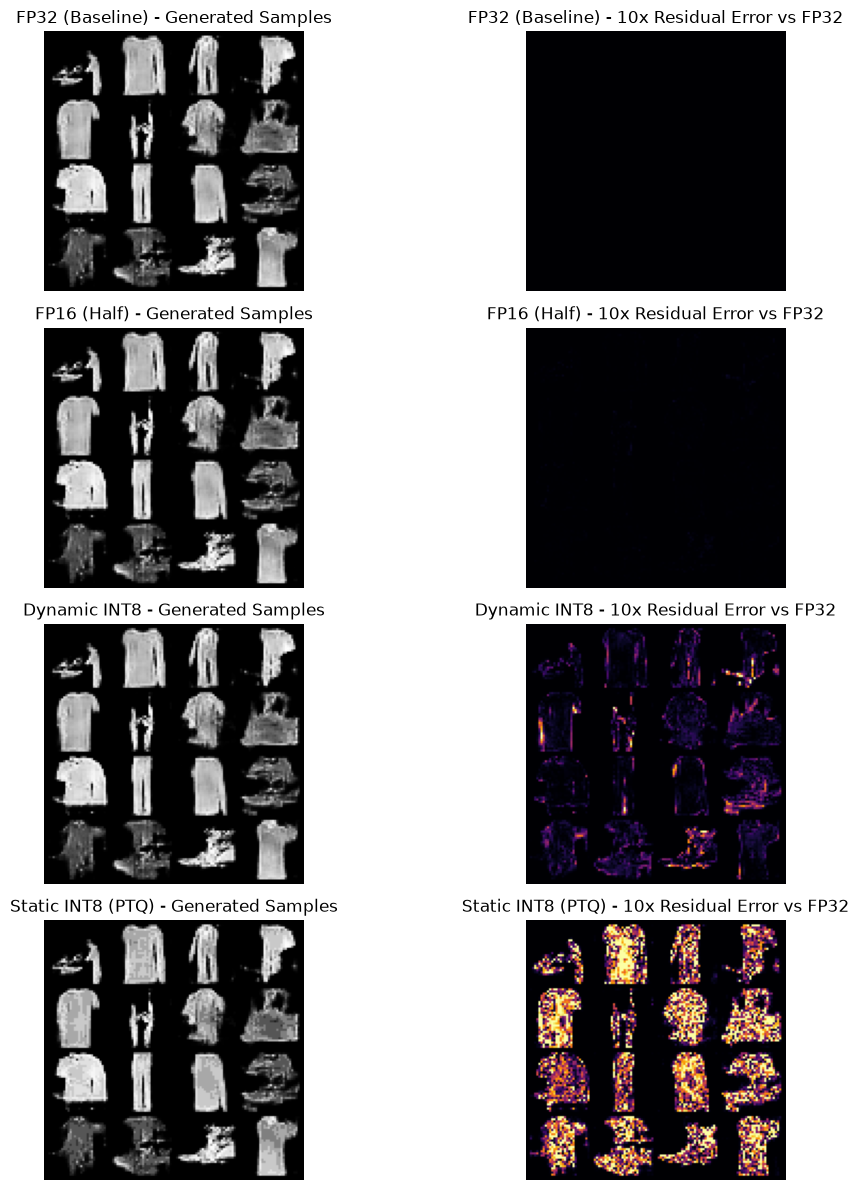

In [7]:
fig, axes = plt.subplots(4, 2, figsize=(12, 12))
num_vis = 16

for idx, (name, out_tensor) in enumerate(outputs.items()):
    # Generated Samples Grid
    sample_grid = make_grid(out_tensor[:num_vis], nrow=4, normalize=True, value_range=(-1, 1))
    axes[idx, 0].imshow(sample_grid.permute(1, 2, 0).numpy(), cmap="gray")
    axes[idx, 0].set_title(f"{name} - Generated Samples")
    axes[idx, 0].axis("off")
    
    # Residual Error Heatmap vs FP32 (Amplified 10x for visibility)
    diff = torch.abs(outputs["FP32 (Baseline)"][:num_vis] - out_tensor[:num_vis]) * 10.0
    diff_grid = make_grid(diff, nrow=4, normalize=False, value_range=(0, 1))
    axes[idx, 1].imshow(diff_grid[0].numpy(), cmap="inferno", vmin=0, vmax=1)
    axes[idx, 1].set_title(f"{name} - 10x Residual Error vs FP32")
    axes[idx, 1].axis("off")

plt.tight_layout()
plt.show()